<a href="https://colab.research.google.com/github/Rushi-Vardhan/sql-ecommerce-analysis/blob/main/sql_ecommerce_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQL Business Analysis: E-commerce Database

**Goal:** Answer business questions about sales, customers and products using SQL (joins, aggregations, CTEs and window functions).

**Data:** Synthetic e-commerce dataset generated with Python (reproducible, seed = 42): 1,000 customers, 40 products, 6,000 orders.

**Tools:** Python, SQLite, pandas, Google Colab

In [24]:
import sqlite3
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# ---- Customers ----
n_customers = 1000
cities = ["Hyderabad", "Bengaluru", "Mumbai", "Delhi", "Chennai", "Pune", "Kolkata"]
signup = pd.to_datetime("2023-01-01") + pd.to_timedelta(rng.integers(0, 700, n_customers), unit="D")
customers = pd.DataFrame({
    "customer_id": range(1, n_customers + 1),
    "city": rng.choice(cities, n_customers, p=[0.20, 0.20, 0.18, 0.18, 0.10, 0.08, 0.06]),
    "signup_date": signup.strftime("%Y-%m-%d"),
})

# ---- Products ----
price_range = {"Electronics": (2000, 40000), "Fashion": (500, 5000), "Home": (800, 15000),
               "Books": (150, 900), "Beauty": (200, 3000)}
categories = np.repeat(list(price_range.keys()), 8)
prices = [int(rng.integers(*price_range[c])) for c in categories]
products = pd.DataFrame({
    "product_id": range(1, 41),
    "product_name": [f"{c} Item {i+1}" for i, c in enumerate(categories)],
    "category": categories,
    "price": prices,
})

# ---- Orders ----
n_orders = 6000
cust_weight = rng.pareto(2, n_customers) + 1          # some customers order more often
order_cust = rng.choice(customers.customer_id, n_orders, p=cust_weight / cust_weight.sum())
signup_series = pd.Series(signup, index=customers.customer_id)
base = pd.to_datetime(signup_series.loc[order_cust].values)
span = np.asarray((pd.Timestamp("2025-12-31") - base).days)
offsets = (rng.random(n_orders) * (span + 1)).astype(int)
order_dates = base + pd.to_timedelta(offsets, unit="D")
orders = pd.DataFrame({
    "order_id": range(1, n_orders + 1),
    "customer_id": order_cust,
    "order_date": order_dates.strftime("%Y-%m-%d"),
    "status": rng.choice(["Delivered", "Cancelled", "Returned"], n_orders, p=[0.88, 0.07, 0.05]),
})

# ---- Order items ----
pop = rng.random(40) + 0.2
pop = pop / pop.sum()
price_map = dict(zip(products.product_id, products.price))
rows, item_id = [], 1
for oid in orders.order_id:
    for pid in rng.choice(products.product_id, rng.integers(1, 5), replace=False, p=pop):
        rows.append((item_id, oid, int(pid), int(rng.integers(1, 4)), price_map[int(pid)]))
        item_id += 1
order_items = pd.DataFrame(rows, columns=["item_id", "order_id", "product_id", "quantity", "unit_price"])

# ---- Load into SQLite ----
conn = sqlite3.connect("ecommerce.db")
for name, d in {"customers": customers, "products": products, "orders": orders, "order_items": order_items}.items():
    d.to_sql(name, conn, if_exists="replace", index=False)

def q(sql):
    return pd.read_sql_query(sql, conn)

print("Database ready")

Database ready


In [25]:
# Q1: How big is the database?
q("""
SELECT (SELECT COUNT(*) FROM customers)   AS customers,
       (SELECT COUNT(*) FROM products)    AS products,
       (SELECT COUNT(*) FROM orders)      AS orders,
       (SELECT COUNT(*) FROM order_items) AS order_items
""")

,customers,products,orders,order_items
0,1000,40,6000,14877


In [26]:
q("""
SELECT p.category,
       COUNT(DISTINCT oi.order_id) AS orders,
       SUM(oi.quantity) AS units_sold,
       ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
JOIN orders o   ON oi.order_id = o.order_id
WHERE o.status = 'Delivered'
GROUP BY p.category
ORDER BY revenue DESC
""")

,category,orders,units_sold,revenue
0,Electronics,2514,6220,170320206.0
1,Home,1872,4360,29012841.0
2,Fashion,2669,6606,19272559.0
3,Beauty,2085,4918,6900002.0
4,Books,1728,3848,2098858.0


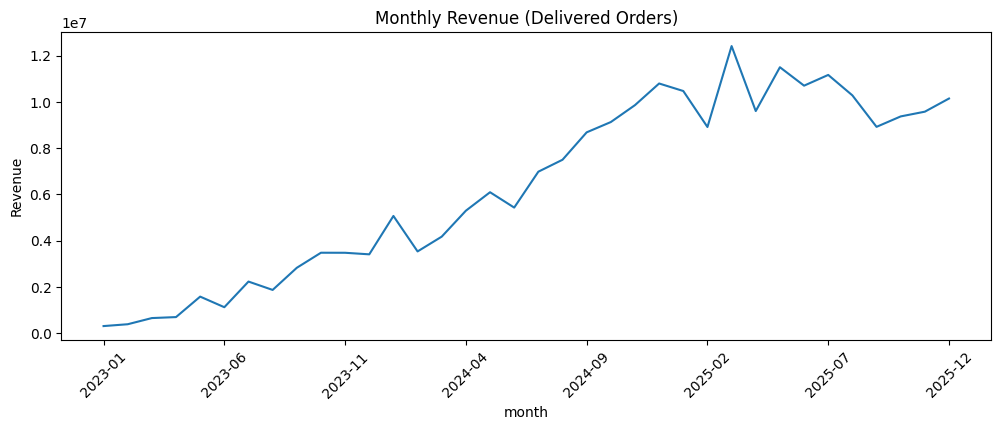

,month,revenue
30,2025-07,11162032.0
31,2025-08,10278654.0
32,2025-09,8918612.0
33,2025-10,9369106.0
34,2025-11,9573924.0
35,2025-12,10142266.0


In [27]:
import matplotlib.pyplot as plt

monthly = q("""
SELECT strftime('%Y-%m', o.order_date) AS month,
       ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.status = 'Delivered'
GROUP BY month
ORDER BY month
""")

monthly.plot(x='month', y='revenue', figsize=(12, 4), title='Monthly Revenue (Delivered Orders)', legend=False)
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

monthly.tail(6)   # shows only the last 6 months as a table

In [28]:
q("""
WITH monthly AS (
    SELECT strftime('%Y-%m', o.order_date) AS month,
           SUM(oi.quantity * oi.unit_price) AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.status = 'Delivered'
    GROUP BY month
)
SELECT month,
       ROUND(revenue, 2) AS revenue,
       ROUND(LAG(revenue) OVER (ORDER BY month), 2) AS prev_month,
       ROUND((revenue - LAG(revenue) OVER (ORDER BY month)) * 100.0
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct
FROM monthly
ORDER BY month DESC
LIMIT 12
""")

,month,revenue,prev_month,mom_growth_pct
0,2025-12,10142266.0,9573924.0,5.9
1,2025-11,9573924.0,9369106.0,2.2
2,2025-10,9369106.0,8918612.0,5.1
3,2025-09,8918612.0,10278654.0,-13.2
4,2025-08,10278654.0,11162032.0,-7.9
5,2025-07,11162032.0,10698115.0,4.3
6,2025-06,10698115.0,11494553.0,-6.9
7,2025-05,11494553.0,9600993.0,19.7
8,2025-04,9600993.0,12408846.0,-22.6
9,2025-03,12408846.0,8911591.0,39.2


In [29]:
q("""
WITH cust_rev AS (
    SELECT c.customer_id, c.city,
           ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.status = 'Delivered'
    GROUP BY c.customer_id, c.city
)
SELECT RANK() OVER (ORDER BY revenue DESC) AS rank, customer_id, city, revenue
FROM cust_rev
ORDER BY rank
LIMIT 10
""")

,rank,customer_id,city,revenue
0,1,638,Mumbai,12493935.0
1,2,179,Hyderabad,5191185.0
2,3,170,Mumbai,3945023.0
3,4,356,Mumbai,3135862.0
4,5,398,Bengaluru,2096200.0
5,6,875,Kolkata,2038466.0
6,7,730,Hyderabad,1515858.0
7,8,299,Delhi,1359523.0
8,9,181,Hyderabad,1312072.0
9,10,214,Pune,1310672.0


In [30]:
q("""
SELECT c.city,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.status = 'Delivered'
GROUP BY c.city
ORDER BY revenue DESC
""")

,city,orders,revenue
0,Mumbai,1275,56696678.0
1,Hyderabad,1161,49402403.0
2,Bengaluru,909,39754953.0
3,Delhi,699,29912702.0
4,Chennai,418,18835484.0
5,Kolkata,392,17585887.0
6,Pune,393,15416359.0


In [31]:
q("""
SELECT status,
       COUNT(*) AS orders,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders), 1) AS pct_of_orders
FROM orders
GROUP BY status
""")

,status,orders,pct_of_orders
0,Cancelled,445,7.4
1,Delivered,5247,87.5
2,Returned,308,5.1


In [32]:
q("""
WITH cust_orders AS (
    SELECT customer_id, COUNT(*) AS n_orders
    FROM orders
    GROUP BY customer_id
)
SELECT CASE WHEN n_orders = 1 THEN 'One-time' ELSE 'Repeat' END AS segment,
       COUNT(*) AS customers,
       ROUND(AVG(n_orders), 1) AS avg_orders
FROM cust_orders
GROUP BY segment
""")

,segment,customers,avg_orders
0,One-time,87,1.0
1,Repeat,893,6.6


In [33]:
q("""
WITH prod_rev AS (
    SELECT p.category, p.product_name,
           SUM(oi.quantity * oi.unit_price) AS revenue
    FROM order_items oi
    JOIN products p ON oi.product_id = p.product_id
    JOIN orders o   ON oi.order_id = o.order_id
    WHERE o.status = 'Delivered'
    GROUP BY p.category, p.product_name
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY category ORDER BY revenue DESC) AS rn
    FROM prod_rev
)
SELECT category, product_name, ROUND(revenue, 2) AS revenue, rn AS rank_in_category
FROM ranked
WHERE rn <= 3
ORDER BY category, rn
""")

,category,product_name,revenue,rank_in_category
0,Beauty,Beauty Item 36,1895284.0,1
1,Beauty,Beauty Item 33,1400276.0,2
2,Beauty,Beauty Item 37,1320840.0,3
3,Books,Books Item 30,732332.0,1
4,Books,Books Item 31,299871.0,2
5,Books,Books Item 28,267670.0,3
6,Electronics,Electronics Item 3,33677974.0,1
7,Electronics,Electronics Item 4,33381234.0,2
8,Electronics,Electronics Item 1,25504520.0,3
9,Fashion,Fashion Item 10,4058458.0,1


In [34]:
q("""
WITH order_totals AS (
    SELECT o.order_id, SUM(oi.quantity * oi.unit_price) AS total
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.status = 'Delivered'
    GROUP BY o.order_id
)
SELECT COUNT(*) AS delivered_orders,
       ROUND(AVG(total), 2) AS avg_order_value,
       ROUND(MIN(total), 2) AS min_order,
       ROUND(MAX(total), 2) AS max_order
FROM order_totals
""")

,delivered_orders,avg_order_value,min_order,max_order
0,5247,43378.02,235.0,257650.0


In [35]:
# Q11: How many customers have never placed an order? (LEFT JOIN)
q("""
SELECT COUNT(*) AS customers_without_orders
FROM customers c
LEFT JOIN orders o ON c.customer_id = o.customer_id
WHERE o.order_id IS NULL
""")

,customers_without_orders
0,20


In [36]:
# Q12: City revenue after excluding the top customer (#638)
q("""
SELECT c.city,
       ROUND(SUM(oi.quantity * oi.unit_price), 2) AS revenue_excl_top_customer
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.status = 'Delivered' AND c.customer_id <> 638
GROUP BY c.city
ORDER BY revenue_excl_top_customer DESC
""")

,city,revenue_excl_top_customer
0,Hyderabad,49402403.0
1,Mumbai,44202743.0
2,Bengaluru,39754953.0
3,Delhi,29912702.0
4,Chennai,18835484.0
5,Kolkata,17585887.0
6,Pune,15416359.0


## Key Insights

- **Revenue is concentrated in Electronics.** Delivered orders generated ₹227.6M in total (5,247 orders). Electronics contributes ₹170.3M (74.8%), followed by Home (12.7%), Fashion (8.5%), Beauty (3.0%) and Books (0.9%).
- **Volume and value tell different stories.** Fashion has the most orders (2,669) and units sold (6,606) but ranks third in revenue, while Electronics earns far more from fewer units.
- **Two products drive the business.** The top two Electronics products (Items 3 and 4) bring in about ₹67M, roughly 29% of all revenue.
- **Revenue grew, then plateaued.** Monthly revenue rose from about ₹0.3M in Jan 2023 to a peak of ₹12.4M in Mar 2025, then stayed between ₹8.9M and ₹12.4M through 2025. Month-over-month changes were volatile in 2025, ranging from -22.6% to +39.2%.
- **Three cities generate 64% of revenue.** Mumbai (₹56.7M), Hyderabad (₹49.4M) and Bengaluru (₹39.8M) lead; Pune is lowest at ₹15.4M.
- **One customer matters a lot.** Customer #638 (Mumbai) spent ₹12.5M, 5.5% of all revenue and 2.4x the second-best customer. Excluding this customer, Mumbai falls behind Hyderabad, so Mumbai's lead depends on a single account. The top 10 customers together account for about 15% of revenue.
- **12.5% of orders bring in no revenue.** 87.5% of orders were delivered, 7.4% cancelled and 5.1% returned.
- **Most customers are repeat buyers.** 893 of 980 customers who ordered (91%) placed more than one order, averaging 6.6 orders; 87 bought once. 20 customers never ordered (LEFT JOIN).
- **Order values vary widely.** The average order value is ₹43,378, with orders ranging from ₹235 to ₹257,650, driven by Electronics pricing.

**Note:** The data is synthetic, so some patterns (such as the high repeat-purchase rate and early revenue growth, which follows customer signups through 2024) come from how the data was generated, not real market behaviour.